# Tutorial 5b - 2D NMR correlation maps


```
      _
    /|_|\   
   / / \ \  
  /_/   \_\  
  \ \   / /  
   \ \_/ /  
    \|_|/  

```
SOPRANO: a Python library for generation, manipulation and analysis of large batches of crystalline structures


*Developed within the CCP-NC project. Copyright STFC 2022–2026*

This tutorial shows how Soprano constructs predicted 2D NMR correlation maps from a `.magres` file: choosing which sites are paired, weighting each pair by a coupling measure, and plotting, editing, and exporting the resulting peak list and contours. It focuses on the 2D workflow. For 1D parameters, chemical shift referencing, and `NMRCalculator`, see [Tutorial 5a](./05a-nmr-parameters.ipynb). For tensor orientations and spin systems exported to SIMPSON or MRSimulator, see [Tutorial 5c](./05c-nmr-tensors-spin-systems.ipynb).

These plots are fast, geometry- and coupling-weighted correlation maps meant to guide assignment and structure comparison—they are not full quantum-mechanical spin simulations and do not model pulse sequences or finite-speed MAS lineshapes.

Prerequisites: a working Soprano installation and the files in `tutorial_data/`. Section 10 builds on `NMRCalculator` and referencing from [Tutorial 5a](./05a-nmr-parameters.ipynb), so read 5a first. Sections marked Advanced are skippable on a first read.

**Contents / suggested route**

- 1 - What a 2D correlation map shows
- 2 - A minimal 2D plot
- 3 - Shielding or shift? References and gradients
- 4 - Filtering peaks by distance
- 5 - Correlation-strength metrics
- 6 - PlotSettings quickstart
- 7 - Choosing peaks yourself
  - 7.1 - Custom pairs with `correlation_strengths`
  - 7.2 - Custom `Peak2D` objects
  - 7.3 - Editing auto-generated peaks
- 8 - Functional-group averaging (CH₃)
- 9 - DQ/SQ ¹H–¹H map of L-alanine
- 10 - Combining 2D and 1D spectra
- 11 - Exporting
  - 11.1 - Peaks to a DataFrame and CSV
  - 11.2 - Contour data
- 12 - Advanced: equivalent-site expansion for dipolar RSS
- 13 - Summary and next steps

In [1]:
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from ase import io as ase_io
from matplotlib.gridspec import GridSpec

from soprano.calculate.nmr import NMRCalculator, NMRData2D, NMRFlags, NMRPlot2D, Peak2D, PlotSettings
from soprano.properties.nmr import JCIsotropy, MSShift

# The 2D plotting style sets 400 dpi, which makes every saved figure very large.
# 150 dpi is enough on screen.
%config InlineBackend.print_figure_kwargs = {'dpi': 150}

# ASE warns whenever Atoms are sliced with NumPy 2.5. NMRData2D slices the
# structure to the requested elements, so this would repeat for every call.
# The warning comes from ASE, not from Soprano, so only this message is hidden.
warnings.filterwarnings(
    'ignore', category=DeprecationWarning,
    message='Setting the shape on a NumPy array',
)

## 1 - What a 2D correlation map shows

In an experimental 2D correlation spectrum, a cross-peak appears at the chemical shifts of two coupled nuclei with an intensity determined by the magnetisation transfer pathway. Soprano represents these predicted correlations as a 2D map of markers (with optional broadened heatmaps or contours) whose sizes reflect how strongly each pair is expected to couple.

In a heteronuclear (HETCOR-type) experiment such as ¹H–¹³C, one axis carries the ¹³C shift and the other carries the ¹H shift (Soprano lets you assign either element to `xelement` or `yelement`; here we place ¹³C on x and ¹H on y). Magnetisation transfers either through space via the dipolar coupling, which falls off as $1/r^3$ and favours spatially close pairs, or through bonds via the J coupling, which follows the bonding network rather than a simple distance law.

A homonuclear ¹H–¹H double-quantum/single-quantum (DQ/SQ) experiment uses the single-quantum shift $\delta_i$ on the x axis and the double-quantum sum frequency $\delta_i + \delta_j$ on the y axis; a DQ peak appears only when two protons are dipolar-coupled. Auto-correlations between equivalent protons ($\delta_i = \delta_j$) therefore lie along the diagonal $y = 2x$ (Section 9).

The strengths in Soprano's 2D plots are structural proxies that control marker sizes and broadened contour weights—not simulated pulse-sequence intensities. The workflow has three pieces: `NMRData2D` finds the pairs, computes their positions and strengths, and stores them as `Peak2D` objects; `PlotSettings` holds the drawing options; and `NMRPlot2D` renders the map (optionally into an existing matplotlib axis). Section 5 compares the available strength metrics.

## 2 - A minimal 2D plot

We start with the simplest case: the C–H correlation of ethanol using default settings. With no `correlation_strength_metric` specified, `NMRData2D` uses `'fixed'`, giving every pair equal strength. Because no references are provided, the axes show magnetic shieldings $\sigma$ in ppm.

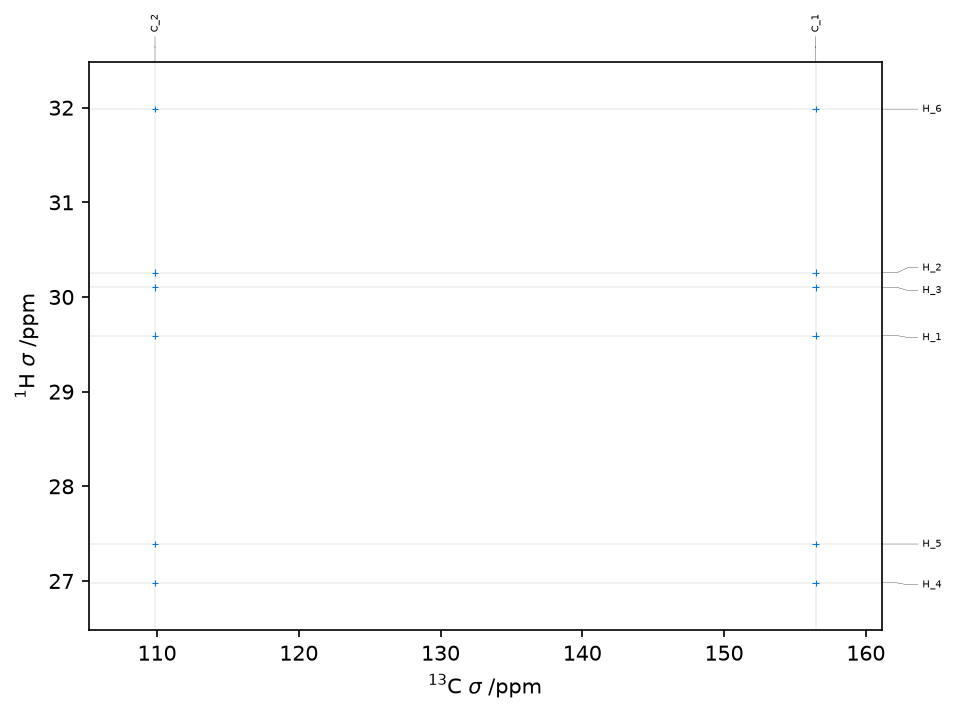

In [2]:
ethanol = ase_io.read('tutorial_data/ethanol.magres')

ch_fixed = NMRData2D(ethanol, xelement='C', yelement='H')
NMRPlot2D(ch_fixed).plot();

*Figure: C–H correlation map of ethanol with equal weights on shielding ($\sigma$, ppm) axes.*

There are twelve markers: each of the two carbons paired with the six protons. Because every strength is equal, all markers have the same size—the plot shows which pairs were selected and where they sit, not how strongly they couple. Shielding axes run in ascending order without reversal; Section 3 converts them to chemical shifts.

## 3 - Shielding or shift? References and gradients

Soprano can plot 2D maps in magnetic shielding $\sigma$ or chemical shift $\delta$. Passing `references` to `NMRData2D` converts $\sigma$ to $\delta$ using the full formula from [Chemical shift referencing](../chemical-shift-referencing), $\delta = (\sigma_{\text{ref}} - \sigma)/(1 - \sigma_{\text{ref}} \times 10^{-6})$, and sets `is_shift=True`. Shift axes are reversed automatically (high ppm on the left for x and at the bottom for y), whereas shielding axes are not reversed because $\sigma$ runs in the opposite direction to $\delta$.

Throughout these tutorials we use the illustrative GIPAW/PBE-like references `H: 31.0` ppm and `C: 170.0` ppm—treat the absolute shifts as approximate and the relative trends as the reliable part. Pass references only for the elements you plot (here C and H).

Passing a gradient $m$ switches an element to the linear calibration $\delta = \sigma_{\text{ref}} + m\,\sigma$ (without the denominator). Because a linear calibration requires an intercept and slope fitted together against experiment, we use the full formula throughout this tutorial and illustrate the effect of a gradient once below.

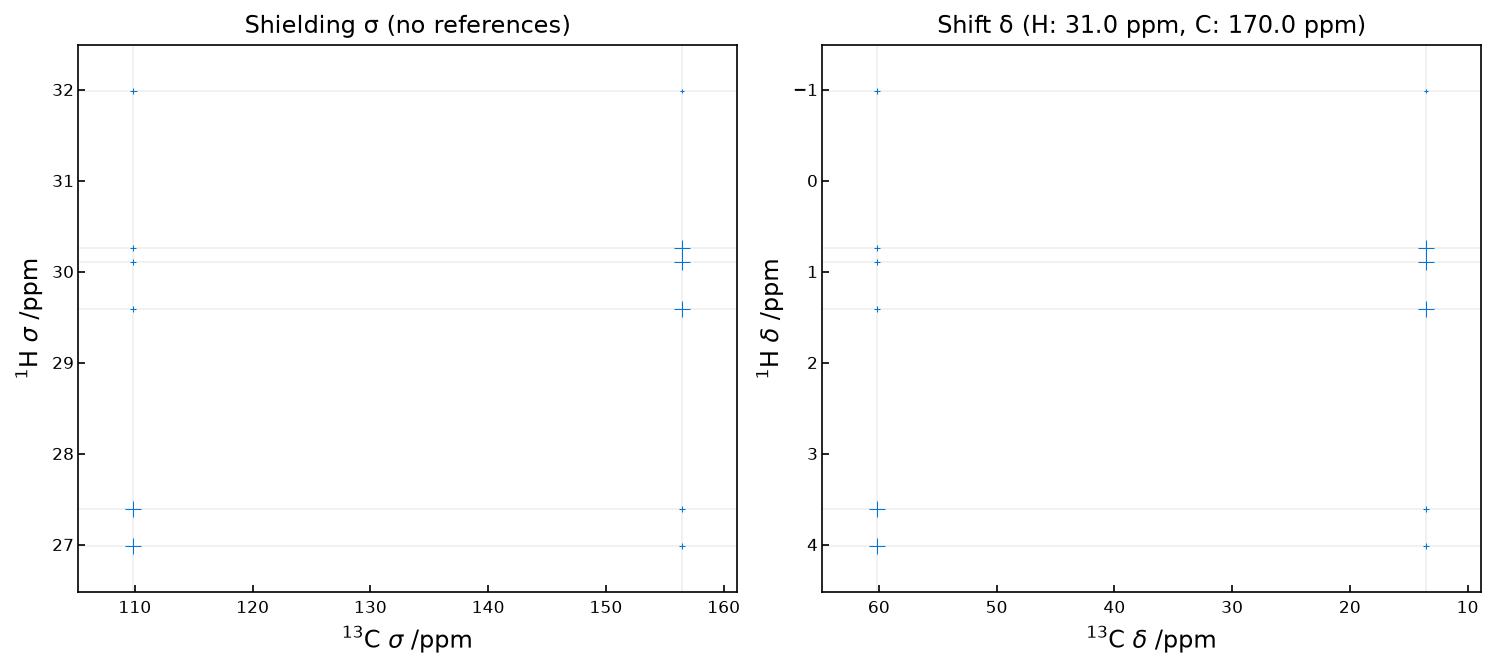

In [3]:
refs = {'H': 31.0, 'C': 170.0}

ch_sigma = NMRData2D(ethanol, xelement='C', yelement='H', correlation_strength_metric='dipolar')
ch_shift = NMRData2D(
    ethanol, xelement='C', yelement='H', correlation_strength_metric='dipolar', references=refs,
)

fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))
NMRPlot2D(ch_sigma, PlotSettings(show_labels=False, max_marker_size=60), ax=axs[0]).plot()
NMRPlot2D(ch_shift, PlotSettings(show_labels=False, max_marker_size=60), ax=axs[1]).plot()
axs[0].set_title('Shielding σ (no references)')
axs[1].set_title('Shift δ (H: 31.0 ppm, C: 170.0 ppm)')
plt.tight_layout();

*Figure: the same ethanol C–H pairs plotted as magnetic shielding $\sigma$ (left) and chemical shift $\delta$ (right).*

Both panels contain the same peaks. In the shielding panel the carbon axis increases to the right; in the shift panel it is reversed, placing the methyl carbon (`C_1`, ~13.5 ppm) on the right and the CH₂ carbon (`C_2`, ~60.2 ppm) on the left.

To see the effect of a gradient, we compare the full formula with a linear fit on the two carbons using a typical ¹³C slope of $-0.98$ (from [Chemical shift referencing](../chemical-shift-referencing)). We slice to carbons only because `MSShift` requires a reference for every element in the structure (and ethanol's oxygen has none). You can pass the same `gradients` dictionary directly to `NMRData2D`.

In [4]:
carbon_idx = [i for i, s in enumerate(ethanol.get_chemical_symbols()) if s == 'C']
carbons = ethanol[carbon_idx]

full_formula = MSShift.get(carbons, references={'C': 170.0})
linear_fit = MSShift.get(carbons, references={'C': 170.0}, gradients={'C': -0.98})

pd.DataFrame(
    {'full formula (ppm)': full_formula, 'linear fit (ppm)': linear_fit},
    index=pd.Index(carbon_idx, name='atom index'),
).round(2)

,full formula (ppm),linear fit (ppm)
atom index,,
6,13.54,16.66
7,60.15,62.34


Changing to the linear form shifts both carbons by 2 to 3 ppm. A linear calibration is only meaningful when intercept and slope are fitted together against experimental shifts (as in [Tutorial 5a](./05a-nmr-parameters.ipynb), Section 3.3); pairing $-0.98$ with the illustrative 170 ppm simply illustrates the magnitude of the effect. The rest of this tutorial uses the full formula.

## 4 - Filtering peaks by distance

`rcut` sets the maximum interatomic distance (in Å) for a pair to be kept. `NMRData2D` uses the minimum-image distance, so periodic neighbours across a cell boundary are included and each pair appears once at its shortest separation. Pairs beyond `rcut` are discarded before peaks are built.

`EDIZUM.magres` is a molecular crystal with 76 H and 60 C atoms in the unit cell. Below we plot all C–H pairs on shift axes and overlay those within 1.5 Å in red.

In [5]:
edizum = ase_io.read('tutorial_data/EDIZUM.magres')
xlims = (-20, 150)  # ppm, ascending order; shift axes are reversed automatically
ylims = (-3, 9)     # ppm

ch_all = NMRData2D(edizum, xelement='C', yelement='H', references=refs)

rcut = 1.5  # Å
ch_cut = NMRData2D(edizum, xelement='C', yelement='H', references=refs, rcut=rcut)

pd.DataFrame(
    {'C–H peaks': [len(ch_all.peaks), len(ch_cut.peaks)]},
    index=['no cutoff', f'rcut = {rcut} Å'],
)

,C–H peaks
no cutoff,285
rcut = 1.5 Å,19


Text(0.5, 1.0, 'EDIZUM C–H pairs: all (blue) and within 1.5 Å (red)')

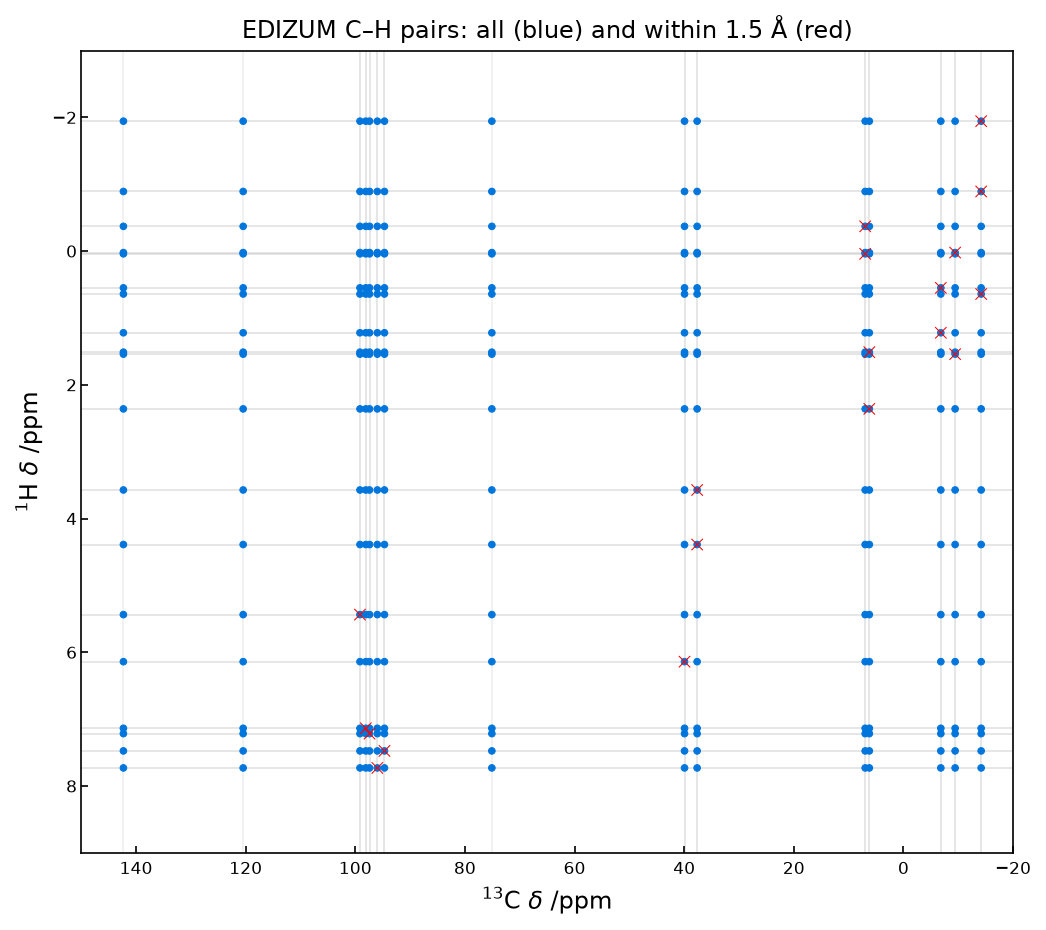

In [6]:
fig, ax = plt.subplots(figsize=(7, 6))
NMRPlot2D(
    ch_all,
    PlotSettings(marker='o', marker_color='C0', max_marker_size=10, show_labels=False,
                 xlim=xlims, ylim=ylims),
    ax=ax,
).plot()
NMRPlot2D(
    ch_cut,
    PlotSettings(marker='x', marker_color='red', max_marker_size=30, show_labels=False,
                 xlim=xlims, ylim=ylims),
    ax=ax,
).plot();
ax.set_title(f'EDIZUM C–H pairs: all (blue) and within {rcut} Å (red)')

*Figure: EDIZUM C–H pairs—all pairs (blue circles) and those with minimum-image distance within 1.5 Å (red crosses).*

The 285 peaks match the 19 symmetry-unique H and 15 symmetry-unique C environments in the crystal ($19 \times 15 = 285$): symmetry-equivalent pairs land at the same shifts and are merged automatically. Under the 1.5 Å cutoff, only directly bonded C–H pairs (~1 Å) survive, collapsing to 19 peaks. Longer-range pairs would receive much smaller weights under the dipolar metric (Section 5); filtering with `rcut` keeps crowded plots readable, so set it to match the interaction range relevant to your experiment.

## 5 - Correlation-strength metrics

`correlation_strength_metric` controls how each pair is weighted. Below we compare four options on ethanol's C–H pairs using the same references and plot settings. Marker sizes are normalised within each panel (so compare relative rankings inside a panel, not absolute marker sizes across panels) and reflect the *magnitude* of the strength rather than its sign.

- `'fixed'`: every pair gets strength 1.
- `'dipolar'`: the dipolar coupling constant in kHz at the minimum-image distance (falls off as $1/r^3$).
- `'jcoupling'`: the isotropic J coupling in Hz from the `isc` tensors in the `.magres` file (present in `ethanol.magres`, though absent in `alanine.magres` and `EDIZUM.magres`).
- `'dipolar_rss'`: the root-sum-square (in kHz) of dipolar couplings from the second site's periodic images within `rss_cutoff`. This is the standard metric for homonuclear DQ/SQ maps (Section 9).

Other options (`'distance'`, `'inversedistance'`, and `'dipolar2'`) are also available in the API.

In [7]:
metric_data = {
    metric: NMRData2D(
        ethanol, xelement='C', yelement='H', references=refs,
        correlation_strength_metric=metric,
    )
    for metric in ['fixed', 'dipolar', 'jcoupling', 'dipolar_rss']
}

dipolar_data = metric_data['dipolar']
pair_distance = {
    (int(i), int(j)): d for (i, j), d in zip(dipolar_data.pairs, dipolar_data.pair_distances)
}
strength = {
    metric: {(p.idx_x, p.idx_y): p.correlation_strength for p in data.peaks}
    for metric, data in metric_data.items()
}
labels = {(p.idx_x, p.idx_y): f'{p.xlabel}–{p.ylabel}' for p in dipolar_data.peaks}

table = pd.DataFrame([
    {
        'pair': labels[key],
        'distance (Å)': pair_distance[key],
        'fixed': strength['fixed'][key],
        'dipolar (kHz)': strength['dipolar'][key],
        'J (Hz)': strength['jcoupling'][key],
        'dipolar_rss (kHz)': strength['dipolar_rss'][key],
    }
    for key in strength['dipolar']
])
table.reindex(table['dipolar (kHz)'].abs().sort_values(ascending=False).index).round(2).reset_index(drop=True)

,pair,distance (Å),fixed,dipolar (kHz),J (Hz),dipolar_rss (kHz)
0,C_1–H_3,1.09,1.0,-23.19,106.02,23.19
1,C_2–H_5,1.09,1.0,-23.18,116.38,23.18
2,C_1–H_1,1.09,1.0,-23.05,102.11,23.05
3,C_1–H_2,1.10,1.0,-23.00,104.58,23.00
4,C_2–H_4,1.10,1.0,-22.73,114.88,22.73
5,C_2–H_6,1.95,1.0,-4.08,0.51,4.10
6,C_2–H_3,2.15,1.0,-3.03,-1.85,3.04
7,C_1–H_5,2.16,1.0,-2.99,1.30,3.03
8,C_1–H_4,2.17,1.0,-2.98,3.81,2.99
9,C_2–H_2,2.17,1.0,-2.98,-1.45,3.02


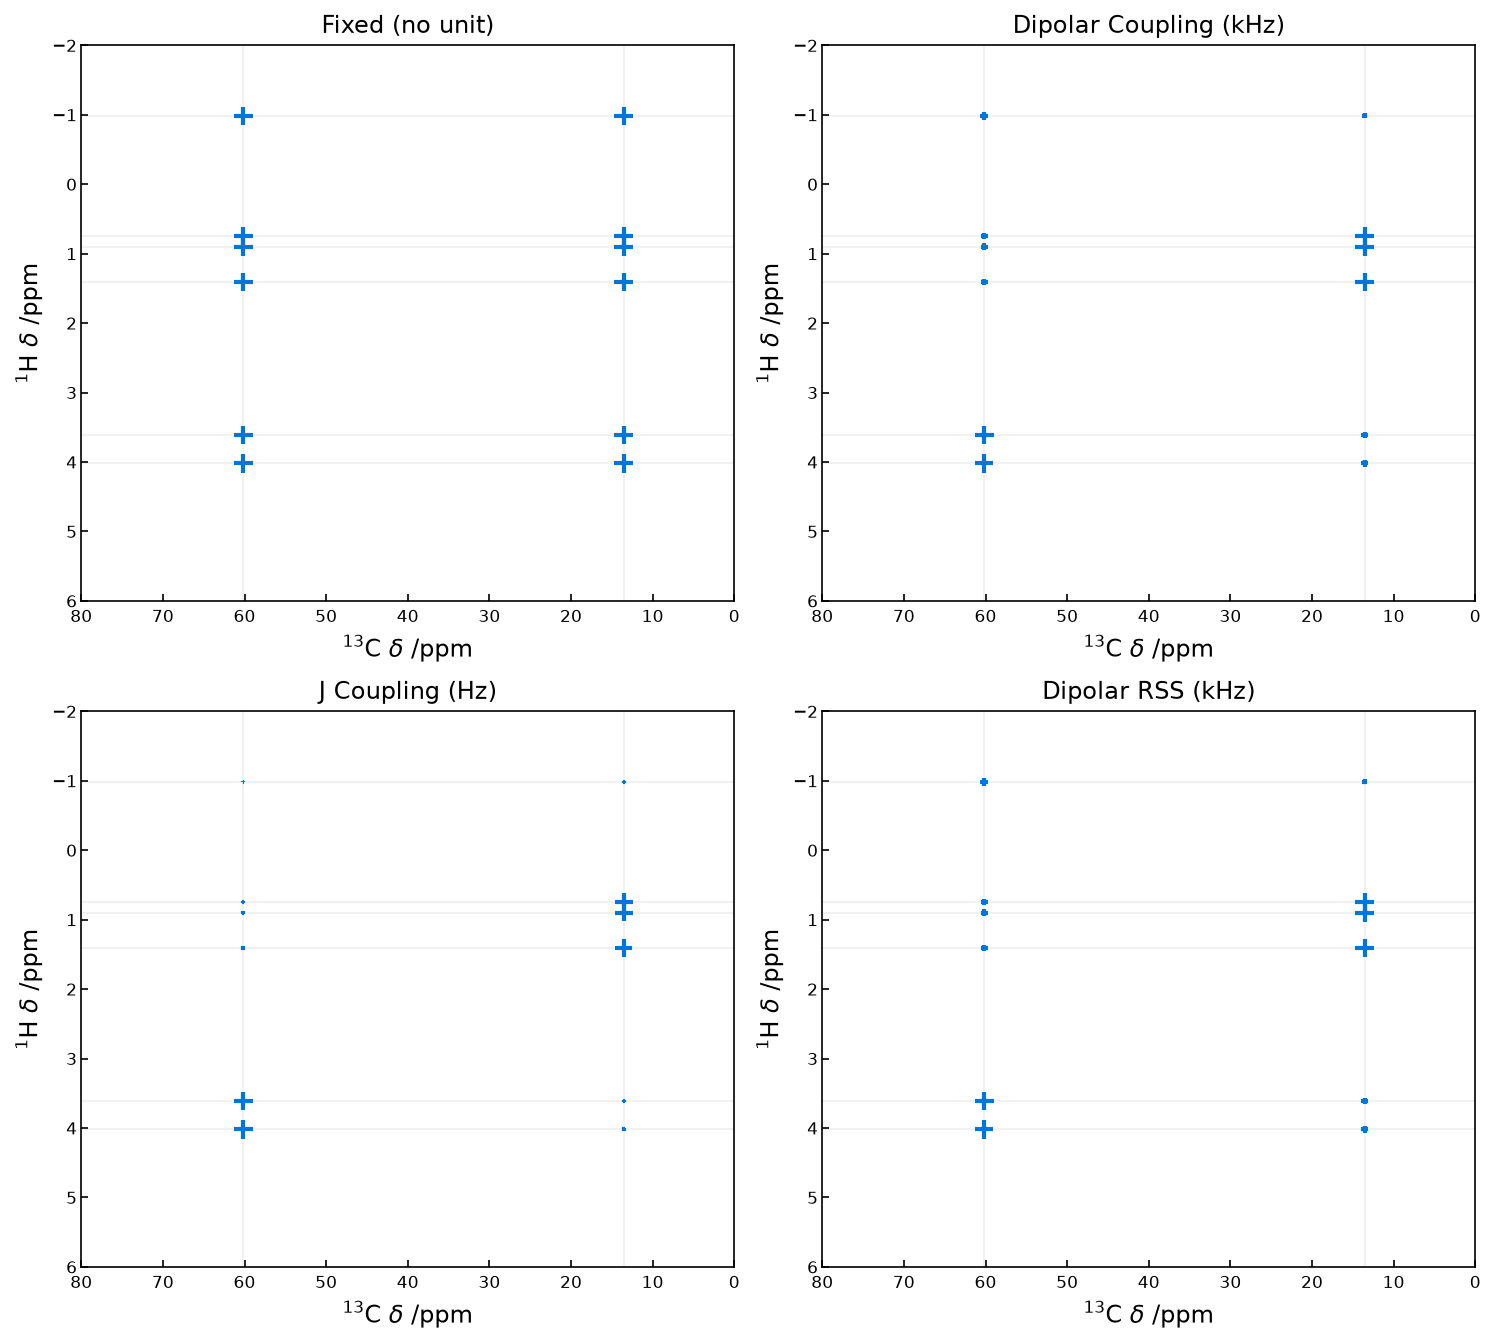

In [8]:
panel_settings = dict(
    show_labels=False, max_marker_size=80, marker_linewidth=2.0,
    xlim=(0, 80), ylim=(-2, 6),
)

fig, axs = plt.subplots(2, 2, figsize=(10, 9))
for ax, (metric, data) in zip(axs.flatten(), metric_data.items()):
    NMRPlot2D(data, PlotSettings(**panel_settings), ax=ax).plot()
    ax.set_title(f'{data.correlation_label} ({data.correlation_unit or "no unit"})')
plt.tight_layout();

*Table (top) and figure (bottom): ethanol C–H distances and correlation strengths sorted by $|d|$, and the corresponding 2D maps with marker sizes normalised within each panel.*

Three points stand out:

1. `'fixed'` weights every pair equally, showing peak positions and pair selection only.
2. `'dipolar'` and `'jcoupling'` both place the one-bond C–H pairs (~1.1 Å, ~23 kHz dipolar, 102–116 Hz J) at the top, while longer-range pairs drop to a few kHz or a few Hz. Unlike dipolar couplings, J couplings change sign and do not follow a monotonic distance law because they travel through bonds.
3. `'dipolar_rss'` agrees with $|\text{dipolar}|$ to within ~4% here because the isolated ethanol molecule sits in a 6 Å cell, so only one periodic image contributes within the 5 Å cutoff. The two diverge when a site has several periodic images or equivalent neighbours within the cutoff—the key case for homonuclear ¹H–¹H DQ/SQ maps (Sections 9 and 12).

**Choosing a metric:** use `'fixed'` to inspect peak positions/topology; `'dipolar'` for through-space heteronuclear proximity (keeping motional averaging in mind—see [Dipolar averaging](../dipolar-averaging)); `'jcoupling'` for through-bond experiments when `isc` tensors are present; and `'dipolar_rss'` for homonuclear DQ/SQ maps with multiple equivalent neighbours.

## 6 - PlotSettings quickstart

`PlotSettings` controls how a 2D map is drawn. Most figures only need a small subset of options:

- `xlim`, `ylim`: axis limits, given in ascending order (reversed automatically for chemical shift plots).
- `marker`, `max_marker_size`, `marker_color`: marker style, maximum size, and colour.
- `show_labels`, `label_fontsize`: peak labels.
- `show_contour`, `show_heatmap`: toggle broadened intensity overlays.
- `x_broadening`, `y_broadening`: overlay linewidth in ppm (defaults to 5% of the peak span in each dimension).
- `contour_levels`, `heatmap_levels`: detail of the overlays.
- `show_connectors`, `show_diagonal`: visual guides for DQ/SQ maps (Section 9).

Key defaults to be aware of:

- `marker='+'`, `show_markers=True`, `show_heatmap=False`, `show_contour=False`.
- `broadening_type='lorentzian'` and `intensity_range=(10.0, 100.0)` (inherited by `contour_range` and `heatmap_range` unless overridden).
- `heatmap_grid_size` defaults to 600 for Lorentzian and 150 for Gaussian broadening.
- Every field is validated on assignment, so invalid markers, colormaps, or ranges raise an error immediately.

The full field reference is in the API documentation. Below is a C–H map combining markers, a heatmap, and contours on shift axes.

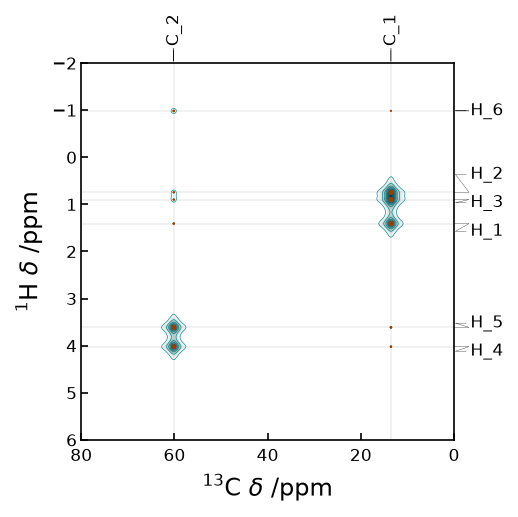

In [9]:
ch_dipolar = NMRData2D(ethanol, xelement='C', yelement='H', references=refs,
                       correlation_strength_metric='dipolar')

plot_settings = PlotSettings(
    xlim=(0, 80),
    ylim=(-2, 6),
    marker='o',
    marker_color='C1',
    max_marker_size=4,
    show_labels=True,
    label_fontsize=8,
    show_heatmap=True,
    show_contour=True,
    x_broadening=2.0,
    y_broadening=0.2,
    heatmap_grid_size=400,
    heatmap_levels=40,
    contour_levels=8,
    contour_color='teal',
    contour_linewidth=0.3,
    colormap='bone_r',
)

NMRPlot2D(ch_dipolar, plot_settings).plot();

*Figure: ethanol C–H dipolar correlation map with markers, heatmap, and contour overlays (shift $\delta$, ppm).*

The heatmap and contours are broadened representations of the same peaks: the 1.09 Å one-bond pairs dominate, while longer-range pairs appear as faint tails. Set `x_broadening` and `y_broadening` to match realistic experimental linewidths rather than just smoothing the image, as overly broad widths merge neighbouring peaks.

## 7 - Choosing peaks yourself

Automatic peak generation is convenient, but you may want to choose the pairs, the strengths or the peaks themselves. There are three ways to do it, in increasing order of control.

### 7.1 - Custom pairs with `correlation_strengths`

Pass `pairs` as a list of `(i, j)` atom-index tuples together with a matching `correlation_strengths` list (normalised to the largest value). Indices always refer to the input `Atoms` object you pass to `NMRData2D`, even if you enable symmetry reduction (`reduce=True`, which collapses a crystal to its asymmetric unit; see Section 12). Each `i` must belong to `xelement` and each `j` to `yelement`, otherwise `NMRData2D` raises an error identifying the mismatched atom.

When `reduce=True`, Soprano remaps each pair onto the reduced asymmetric-unit sites for peak positions and labels, and emits a `UserWarning` describing the remapping; distances and couplings are still evaluated on the exact atoms you requested in the input structure.

Below we assign arbitrary strengths (1, 2, 3) to illustrate the mechanism—with real data, pass calculated or measured values. Atom 6 is the methyl carbon `C_1`, and atoms 3 to 5 are the methylene and hydroxyl protons (`H_4`–`H_6`).

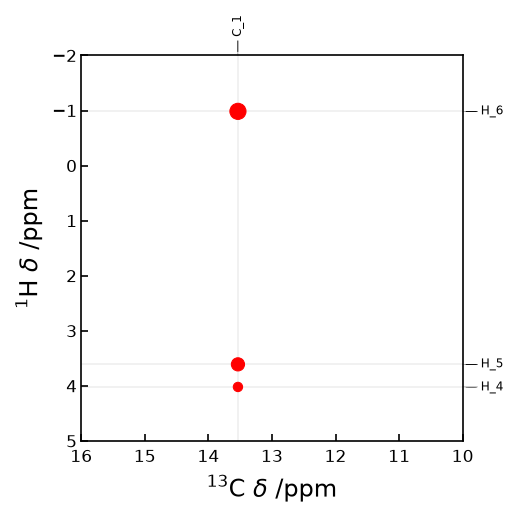

In [10]:
pairs = [(6, 3), (6, 4), (6, 5)]
custom_strengths = [1, 2, 3]

custom = NMRData2D(
    ethanol,
    xelement='C',
    yelement='H',
    references=refs,
    pairs=pairs,
    correlation_strengths=custom_strengths,
)
NMRPlot2D(
    custom,
    PlotSettings(xlim=(10, 16), ylim=(-2, 5), marker='o', marker_color='red',
                 max_marker_size=60),
).plot();

*Figure: three custom C–H pairs of `C_1` with arbitrary strengths 1, 2, and 3 drawn as marker sizes (shift $\delta$, ppm).*

Only the three chosen pairs appear, and the largest marker belongs to the pair with strength 3. Because marker sizes are scaled relative to the largest strength, the absolute values do not matter.

### 7.2 - Custom `Peak2D` objects

For complete control, construct `Peak2D` objects directly with `x`, `y`, labels, `correlation_strength`, and optional colour. No `Atoms` object is required (`atoms=None`), which is convenient when plotting peaks loaded from a CSV file or another program (`pairs` and `correlation_strengths` are ignored in this mode).

Below we use synthetic shifts to illustrate the API. Because the coordinates are already chemical shifts, we set `is_shift=True` so the axes are labelled as $\delta$ and reversed.

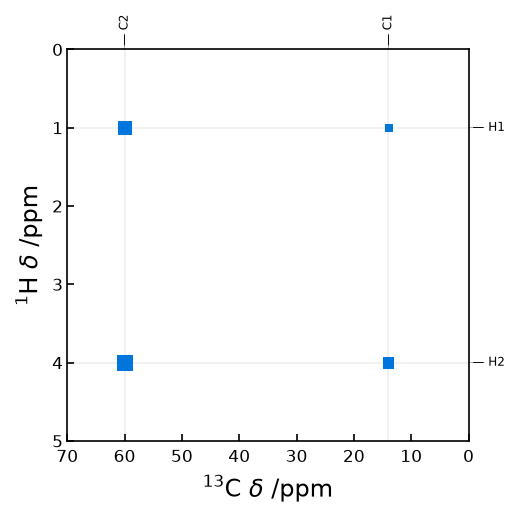

In [11]:
c_shifts = [14.0, 60.0]   # synthetic carbon shifts (ppm)
h_shifts = [1.0, 4.0]     # synthetic proton shifts (ppm)
strengths = [1, 2, 3, 4]

peaks = []
for iC, c_shift in enumerate(c_shifts):
    for iH, h_shift in enumerate(h_shifts):
        peaks.append(Peak2D(
            c_shift,
            h_shift,
            f'C{iC + 1}',
            f'H{iH + 1}',
            correlation_strength=strengths[iC * len(h_shifts) + iH],
        ))

custom_peaks = NMRData2D(
    None,
    peaks=peaks,
    is_shift=True,
    x_axis_label=r"$\mathrm{^{13}C}$ $\delta$ /ppm",
    y_axis_label=r"$\mathrm{^{1}H}$ $\delta$ /ppm",
)

NMRPlot2D(
    custom_peaks,
    PlotSettings(marker='s', xlim=(0, 70), ylim=(0, 5), max_marker_size=50),
).plot();

*Figure: four user-defined peaks at invented shifts, with strengths 1 to 4 shown as square marker sizes.*

Each peak has its own strength and position. The square markers are scaled by strength, and the axes are reversed because `is_shift=True`.

### 7.3 - Editing auto-generated peaks

Often the simplest approach is to let Soprano generate the peaks and then edit some of them. The example here sets each C–H strength to the isotropic J coupling. We use ¹H and ¹³C, the isotopes of interest for this pair.

`JCIsotropy` is computed once for all C and H atoms, outside the loop, which is much faster than one call per peak. Its keys are `(i, j)` pairs with `i < j`, so each peak index pair is sorted before the lookup.

The peak indices refer to the element-selected structure stored in `nmr_edit.atoms`, not to the full cell. The J couplings are therefore computed for that structure as well.

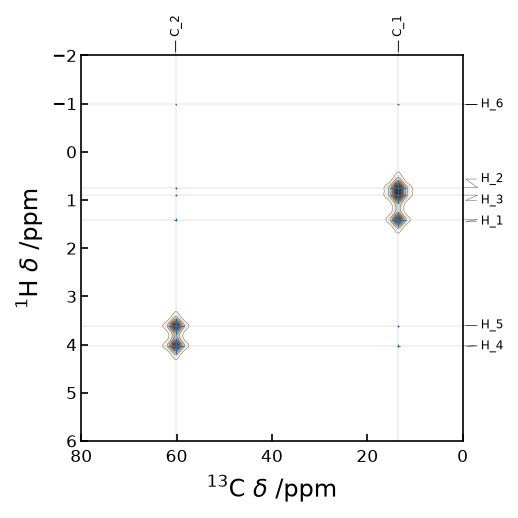

In [12]:
isotopes = {'C': 13, 'H': 1}
nmr_edit = NMRData2D(ethanol, xelement='C', yelement='H', references=refs, isotopes=isotopes)

symbols = nmr_edit.atoms.get_chemical_symbols()
c_idx = [i for i, s in enumerate(symbols) if s == 'C']
h_idx = [i for i, s in enumerate(symbols) if s == 'H']
j_iso = JCIsotropy.get(nmr_edit.atoms, tag='isc', sel_i=c_idx, sel_j=h_idx, isotopes=isotopes)

for peak in nmr_edit.peaks:
    i, j = sorted([peak.idx_x, peak.idx_y])
    peak.correlation_strength = j_iso[(i, j)]

NMRPlot2D(
    nmr_edit,
    PlotSettings(show_heatmap=True, show_contour=True, x_broadening=2.0, y_broadening=0.2,
                 xlim=(0, 80), ylim=(-2, 6), max_marker_size=60),
).plot();

*Figure: ethanol C–H pairs weighted by isotropic J coupling (Hz) on shift axes.*

The strong markers correspond to the one-bond $^1J(\text{C–H})$ couplings of the methyl and methylene groups (~102–116 Hz), while the weak markers are two- and three-bond couplings of a few hertz or less. Marker sizes reflect $|J|$.

Because `nmr_edit` was originally built with the default `'fixed'` metric and then edited in place, its `correlation_label` metadata still reads `"Fixed"`—specify the actual metric in your figure caption rather than relying on that attribute.

## 8 - Functional-group averaging (CH₃)

In many molecular solids, the three protons of a rapidly rotating methyl group are chemically equivalent on the NMR timescale. Passing `average_group='CH3'` to `NMRData2D` merges the three H sites of each CH₃ group into a single representative peak.

Merging happens at the peak level after couplings are computed from the atomic coordinates, updating three quantities:

1. **Position ($x, y$):** the mean isotropic shift of the group's protons.
2. **Coupling strength:** for the `'dipolar'` metric, Soprano computes the rotationally averaged dipolar *tensor* of the group rather than averaging three scalar constants (scalar averaging overestimates the residual coupling; see [Dipolar averaging](../dipolar-averaging)).
3. **Multiplicity:** the group size (3 for CH₃), which weights both heatmap intensity and marker size so a CH₃ peak carries three times the weight of a single proton with the same effective coupling.

Use `average_group` only when the group is rotating rapidly on the NMR timescale—typically valid for CH₃ at room temperature, but not in the cryogenic rigid limit.

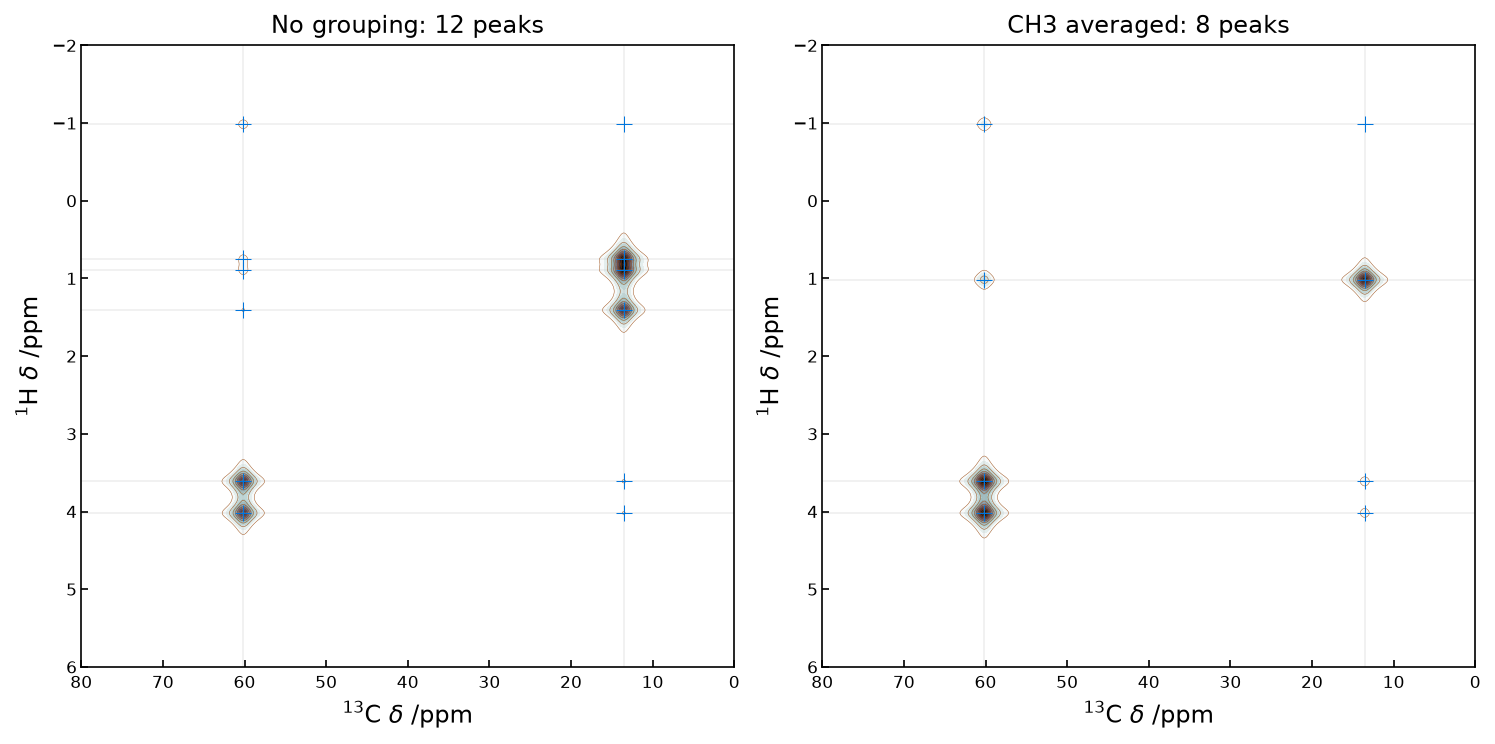

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

ch3_kw = dict(xelement='C', yelement='H', references=refs, correlation_strength_metric='dipolar')
heatmap_kw = dict(
    show_heatmap=True, show_contour=True, show_labels=False,
    x_broadening=2.0, y_broadening=0.2, colormap='bone_r',
    scale_markers=False, max_marker_size=60, xlim=(0, 80), ylim=(-2, 6),
)

plain = NMRData2D(ethanol, **ch3_kw)
NMRPlot2D(plain, PlotSettings(**heatmap_kw), ax=axes[0]).plot()
axes[0].set_title(f'No grouping: {len(plain.peaks)} peaks')

grouped = NMRData2D(ethanol, average_group='CH3', **ch3_kw)
NMRPlot2D(grouped, PlotSettings(**heatmap_kw), ax=axes[1]).plot()
axes[1].set_title(f'CH3 averaged: {len(grouped.peaks)} peaks')
plt.tight_layout();

In [14]:
group_table = pd.DataFrame([
    {
        'C site': p.xlabel,
        'H site(s)': p.ylabel,
        'multiplicity': p.multiplicity,
        'dipolar (kHz)': p.correlation_strength,
        'weight = |strength| × multiplicity': abs(p.correlation_strength) * p.multiplicity,
    }
    for p in grouped.peaks
])
group_table.sort_values('weight = |strength| × multiplicity', ascending=False).round(2).reset_index(drop=True)

,C site,H site(s),multiplicity,dipolar (kHz),weight = |strength| × multiplicity
0,C_2,H_5,1,-23.18,23.18
1,C_2,H_4,1,-22.73,22.73
2,C_1,"H_1,H_2,H_3",3,7.26,21.78
3,C_2,"H_1,H_2,H_3",3,-1.98,5.95
4,C_2,H_6,1,-4.08,4.08
5,C_1,H_5,1,-2.99,2.99
6,C_1,H_4,1,-2.98,2.98
7,C_1,H_6,1,-1.67,1.67


*Figure and table: ethanol C–H correlation map without grouping (left) and with CH₃ averaging (right). Marker size is fixed so the heatmap conveys peak weight.*

Averaging replaces each trio of methyl protons with one peak per carbon. The two CH₃ peaks (`C_1`–CH₃ and `C_2`–CH₃) sit at the mean methyl ¹H shift with multiplicity 3, so each appears as a single strong feature weighted by three times its averaged coupling, while all other pairs retain multiplicity 1.

Notice also that the averaged coupling is much smaller than the static value and has the opposite sign: `C_1`–CH₃ is about $+7.3\text{ kHz}$ versus $-23\text{ kHz}$ statically. For a C–H bond at the tetrahedral angle $\theta \approx 70.5^\circ$ to the three-fold rotation axis, fast rotation scales the static dipolar coupling by $(3\cos^2\theta - 1)/2 = -1/3$. The ratio here is about $-0.32$, closely matching the ideal three-fold jump model.

## 9 - DQ/SQ ¹H–¹H map of L-alanine

Setting `yaxis_order='2Q'` switches from a standard SQ/SQ map to a double-quantum/single-quantum (DQ/SQ) map: the x axis shows the single-quantum ¹H shift $\delta_i$, and the y axis shows the double-quantum sum frequency $\delta_i + \delta_j$.

A dipolar-coupled pair of distinct sites $i$ and $j$ produces an **off-diagonal cross-peak pair** (sometimes called a *roofing pair*) sharing the same DQ coordinate—one peak at $x = \delta_i$ and the other at $x = \delta_j$—joined by horizontal grey connectors (`show_connectors=True`). An **auto-correlation** between equivalent protons ($\delta_i = \delta_j$) lies on the dashed diagonal $y = 2x$ (`show_diagonal=True`).

L-alanine has three ¹H environments: NH₃⁺ near 8.5 ppm, CH near 4 ppm, and CH₃ near 1 ppm. We average the rotating methyl and ammonium groups with `average_group='CH3,NH3'` and weight pairs with `'dipolar_rss'`, which sums the dipolar couplings of each proton to its equivalent neighbours.

We use the same illustrative ¹H reference (31.0 ppm) with no gradient. `alanine.magres` contains 28 H atoms; `rcut=6.0` keeps H–H pairs within 6 Å, and we raise `rss_cutoff` from its 5.0 Å default to 8.0 Å (`rss_cutoff` should be at least as large as `rcut` to avoid incomplete-cutoff warnings).

In [15]:
alanine = ase_io.read('tutorial_data/alanine.magres')

dq = NMRData2D(
    alanine,
    xelement='H',
    yelement='H',
    yaxis_order='2Q',
    references={'H': 31.0},
    rcut=6.0,
    correlation_strength_metric='dipolar_rss',
    rss_cutoff=8.0,
    average_group='CH3,NH3',
)

dq_table = pd.DataFrame([
    {
        'SQ (ppm)': p.x,
        'DQ (ppm)': p.y,
        'RSS (kHz)': abs(p.correlation_strength),
        'multiplicity': p.multiplicity,
        'type': 'auto' if abs(p.y - 2 * p.x) < 0.05 else 'cross',
    }
    for p in dq.peaks
])
dq_table.sort_values('RSS (kHz)', ascending=False).head(8).round(2).reset_index(drop=True)

,SQ (ppm),DQ (ppm),RSS (kHz),multiplicity,type
0,8.48,16.96,25.14,24,auto
1,0.99,1.99,22.32,24,auto
2,8.48,12.40,7.78,12,cross
3,3.92,12.40,7.78,12,cross
4,0.99,4.91,6.67,12,cross
5,3.92,4.91,6.67,12,cross
6,0.99,1.99,5.91,36,auto
7,8.48,9.47,5.70,36,cross


Text(0.5, 1.0, 'DQ/SQ ¹H–¹H, L-alanine (rcut = 6 Å, RSS cutoff = 8 Å)')

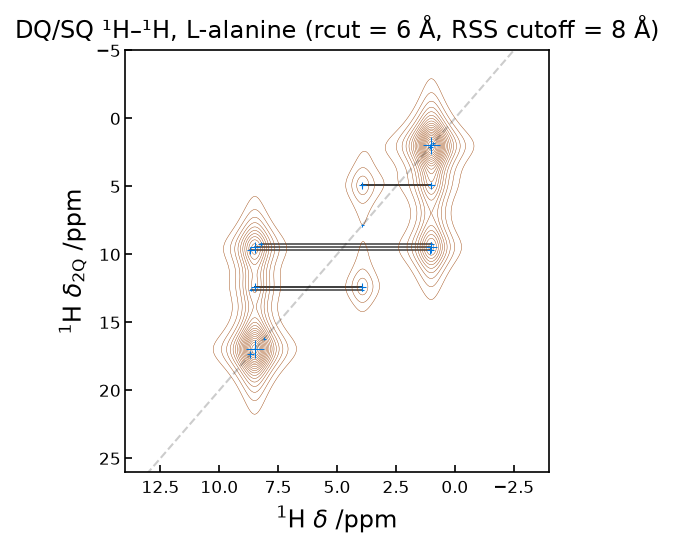

In [16]:
dq_settings = PlotSettings(
    show_contour=True,
    show_markers=True,
    show_connectors=True,
    show_diagonal=True,
    show_labels=False,
    show_lines=False,
    x_broadening=1.2,
    y_broadening=3.1,
    colormap='bone_r',
    contour_levels=20,
    contour_linewidth=0.2,
    scale_markers=True,
    max_marker_size=80,
    heatmap_grid_size=600,
    broadening_type='lorentzian',
    xlim=(-4, 14),
    ylim=(-5, 26),
)

fig, ax = NMRPlot2D(dq, dq_settings).plot()
ax.set_title('DQ/SQ ¹H–¹H, L-alanine (rcut = 6 Å, RSS cutoff = 8 Å)')

*Figure: DQ/SQ ¹H–¹H correlation map of L-alanine, with the dashed diagonal marking $\text{DQ} = 2\,\text{SQ}$ and grey connectors joining off-diagonal cross-peak pairs (shift $\delta$, ppm).*

The two strongest features lie on the diagonal: the auto-correlations of the averaged NH₃⁺ group (~8.5 ppm SQ, 17 ppm DQ) and CH₃ group (~1.0 ppm SQ, 2.0 ppm DQ), reflecting the strong dipolar couplings between protons within each group. Off the diagonal, the CH–NH₃⁺ cross-peak pair sits at a DQ shift of ~12.4 ppm (the sum of the two SQ shifts).

Two caveats apply: the DQ sum-shift axis represents a single frequency scale only in the homonuclear case (where both spins share one Larmor frequency), and dipolar RSS is a proxy for DQ coupling strength rather than a build-up curve simulation, so peak heights are indicative rather than quantitative.

## 10 - Combining 2D and 1D spectra

For publication figures it is often helpful to flank a 2D correlation map with 1D margin spectra. Create the matplotlib `GridSpec` layout yourself and pass the central axis to `NMRPlot2D`. The 1D spectra below come from `NMRCalculator` using the same references as the 2D map, so the peaks align directly.

`NMRCalculator` already applies a default powder average (`N = 8`), so no `set_powder` call is needed. With references set, `min_freq` and `max_freq` are shift limits matching the returned axis. The 1D margin spectra are shown without an intensity axis because their units are arbitrary. Note that these 1D spectra are independent simulations, not projections summed from the 2D contour grid.

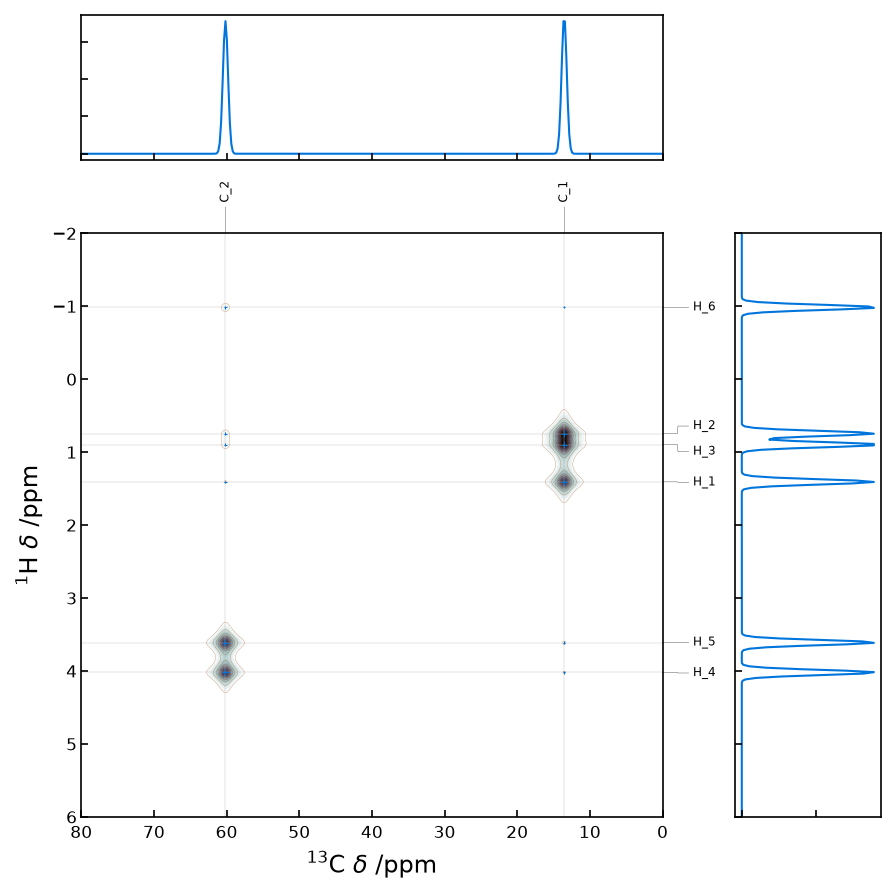

In [17]:
ncalc = NMRCalculator(ethanol, larmor_frequency=400, larmor_units='MHz')  # 9.4 T, 400 MHz ¹H
ncalc.set_reference(170.0, '13C')
ncalc.set_reference(31.0, '1H')

xlims = (0, 80)    # ppm, shift
ylims = (-2, 6)    # ppm, shift

c_spec, c_freq = ncalc.spectrum_1d(
    '13C', effects=NMRFlags.MAS, min_freq=xlims[0], max_freq=xlims[1],
    bins=400, freq_broad=0.5,
)
h_spec, h_freq = ncalc.spectrum_1d(
    '1H', effects=NMRFlags.MAS, min_freq=ylims[0], max_freq=ylims[1],
    bins=400, freq_broad=0.05,
)

fig = plt.figure(figsize=(6, 6))
gs = GridSpec(2, 2, width_ratios=[4, 1], height_ratios=[1, 4])

ax_top = fig.add_subplot(gs[0, 0])
ax_top.plot(c_freq, c_spec, lw=1)
ax_top.set_xlim(xlims[1], xlims[0])
ax_top.tick_params(labelbottom=False, labelleft=False)

ax_right = fig.add_subplot(gs[1, 1])
ax_right.plot(h_spec, h_freq, lw=1)
ax_right.set_ylim(ylims[1], ylims[0])
ax_right.tick_params(labelbottom=False, labelleft=False)

ax_2d = fig.add_subplot(gs[1, 0])
ch_grid = NMRData2D(ethanol, xelement='C', yelement='H', references=refs,
                    correlation_strength_metric='dipolar')
NMRPlot2D(
    ch_grid,
    PlotSettings(
        xlim=xlims, ylim=ylims,
        show_heatmap=True, show_contour=True,
        x_broadening=2.0, y_broadening=0.2,
        heatmap_grid_size=400, heatmap_levels=40,
        contour_levels=10, contour_linewidth=0.1,
        colormap='bone_r',
    ),
    ax=ax_2d,
).plot()
fig.subplots_adjust(wspace=0.2, hspace=0.2);

*Figure: ethanol C–H dipolar correlation map (centre) flanked by simulated 1D infinite-speed MAS ¹³C (top) and ¹H (right) spectra at 9.4 T (shift $\delta$, ppm).*

The 1D lines match the 2D map because both share the same references and axis direction: ¹³C shows the methyl and methylene carbons, and ¹H shows the three proton environments (as discussed in [Tutorial 5a](./05a-nmr-parameters.ipynb), Section 3.2, the isolated-molecule geometry and illustrative reference place the hydroxyl proton near −1 ppm). Because the 1D spectra assume infinite-speed MAS, their linewidths are set solely by `freq_broad`.

## 11 - Exporting

Two outputs are commonly useful downstream: the peak list (compact and human-readable) and the broadened contour grid (for external NMR processing software). Note that contour export is currently marked experimental in Soprano (`export_contour_data` emits a one-time warning per session), so check the exported axes against the peak list before relying on them in external tools.

All files below are written to a temporary output folder (`tutorial_data/_tmp_output/`).

### 11.1 - Peaks to a DataFrame and CSV

`to_dataframe()` returns the peak list with positions, labels, strengths, and metadata such as the metric and unit. Because references are set, `x` and `y` are chemical shifts in ppm.

In [18]:
outdir = os.path.join('tutorial_data', '_tmp_output')
os.makedirs(outdir, exist_ok=True)

peak_table = ch_dipolar.to_dataframe()
peak_table.to_csv(os.path.join(outdir, 'ethanol_ch_peaks.csv'), index=False)

peak_table[['x', 'y', 'xlabel', 'ylabel', 'correlation_strength', 'correlation_unit']].round(2)

,x,y,xlabel,ylabel,correlation_strength,correlation_unit
0,13.54,1.41,C_1,H_1,-23.05,kHz
1,13.54,0.74,C_1,H_2,-23.00,kHz
2,13.54,0.90,C_1,H_3,-23.19,kHz
3,13.54,4.02,C_1,H_4,-2.98,kHz
4,13.54,3.61,C_1,H_5,-2.99,kHz
5,13.54,-0.99,C_1,H_6,-1.67,kHz
6,60.15,1.41,C_2,H_1,-2.96,kHz
7,60.15,0.74,C_2,H_2,-2.98,kHz
8,60.15,0.90,C_2,H_3,-3.03,kHz
9,60.15,4.02,C_2,H_4,-22.73,kHz


The CSV preserves every column (including metadata), so you can reload it with `pd.read_csv` and check it against your spectrum. `correlation_strength` is given in the unit recorded in `correlation_unit` (here kHz).

### 11.2 - Contour data

`export_contour_data` writes the broadened 2D grid. The three formats demonstrated below require no extra dependencies:

- `'json'`: ssNake JSON format. ssNake uses the Larmor frequencies to display axes in ppm automatically.
- `'npz'`: a NumPy archive containing `X`, `Y`, and `Z` arrays for Python post-processing.
- `'csv'`: a flat table (`x`, `y`, `intensity`) for spreadsheets or plotting tools.

`export_contour_data` also supports `'simpson'` (`TYPE=SPE` text) and `'bruker'` (writes a TopSpin dataset `<name>/1/pdata/1`; requires the optional `nmr-io` / `nmrglue` dependency)—see the `export_contour_data` docstring for full details.

The contour grid is cached across calls with identical grid parameters. Below we pass 9.4 T Larmor frequencies: ¹³C at 100.6 MHz and ¹H at 400.1 MHz. **Important for DQ/SQ maps:** even though the y axis holds $\delta_A + \delta_B$, still pass the *single-quantum* Larmor frequency (e.g. 400.1 MHz for ¹H) for `y_larmor_freq_mhz`—doubling it would halve the ppm scale.

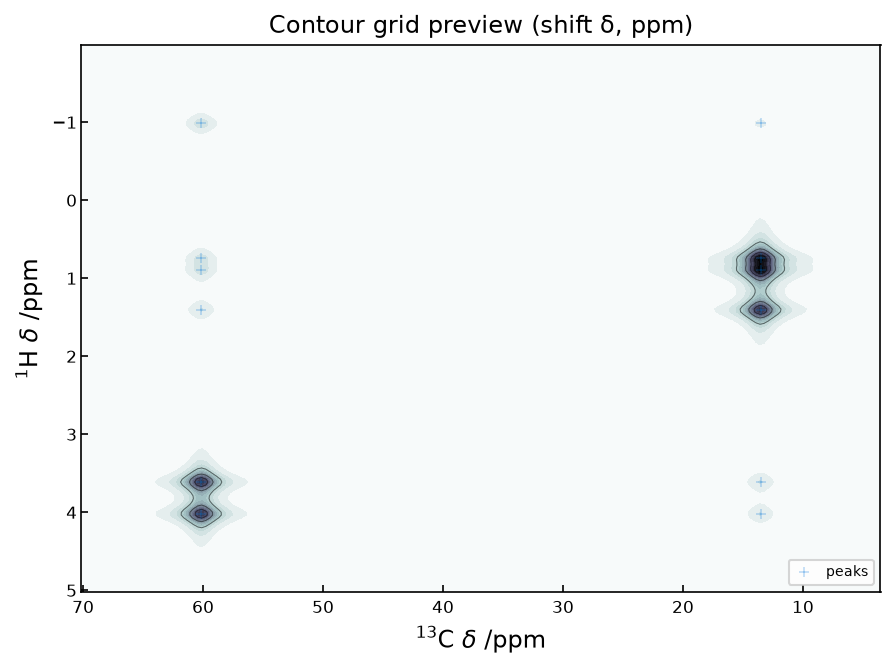

In [19]:
export_kw = dict(
    x_broadening=2.0,
    y_broadening=0.2,
    broadening_type='lorentzian',
    grid_size=200,
    grid_max=1e6,  # scale Z so its maximum is 1e6, a typical experimental intensity scale
)

contour = ch_dipolar.get_contour_data(**export_kw)

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.contourf(contour.X, contour.Y, contour.Z, levels=20, cmap='bone_r')
ax.contour(contour.X, contour.Y, contour.Z, levels=5, colors='k', linewidths=0.5, alpha=0.5)
ax.scatter(
    [p.x for p in ch_dipolar.peaks],
    [p.y for p in ch_dipolar.peaks],
    s=20, marker='+', c='C0', label='peaks',
)
ax.set_xlim(contour.xlims[1], contour.xlims[0])
ax.set_ylim(contour.ylims[1], contour.ylims[0])
ax.set_xlabel(ch_dipolar.x_axis_label)
ax.set_ylabel(ch_dipolar.y_axis_label)
ax.set_title('Contour grid preview (shift δ, ppm)')
ax.legend(loc='lower right')
plt.tight_layout();

In [20]:
ch_dipolar.export_contour_data(
    os.path.join(outdir, 'ethanol_ch.json'), fmt='json',
    x_larmor_freq_mhz=100.6, y_larmor_freq_mhz=400.1,
    **export_kw,
)
ch_dipolar.export_contour_data(os.path.join(outdir, 'ethanol_ch.npz'), fmt='npz', **export_kw)
ch_dipolar.export_contour_data(os.path.join(outdir, 'ethanol_ch.csv'), fmt='csv', **export_kw)

written = []
for name in ['ethanol_ch.json', 'ethanol_ch.npz', 'ethanol_ch.csv', 'ethanol_ch_peaks.csv']:
    path = os.path.join(outdir, name)
    written.append({'file': name, 'size (kB)': round(os.path.getsize(path) / 1024, 1)})
pd.DataFrame(written)

2D spectrum export (Bruker TopSpin, ssNake, SIMPSON, NPZ, CSV, plain text) is experimental: formats and parameters may change. Check exported axes against the peak list before relying on them.


,file,size (kB)
0,ethanol_ch.json,1595.5
1,ethanol_ch.npz,304.2
2,ethanol_ch.csv,2213.4
3,ethanol_ch_peaks.csv,1.6


The grid is 200 by 200 points, so the files are a few megabytes at most. Check that the axes match the peak list before you use the files elsewhere. If you open the JSON file in ssNake, confirm that its ppm axis matches the peaks in `ethanol_ch_peaks.csv`.

## 12 - Advanced: equivalent-site expansion for dipolar RSS

*Skippable on a first read; relevant only when running `dipolar_rss` on a full unit cell (`reduce=False`).*

The `dipolar_rss` metric sums the squared dipolar couplings from images of the second site to the first site within `rss_cutoff`. `rss_expand_j` controls which equivalent atoms join that sum:

- `'periodic_images'` (default): only periodic images of the single second-site atom.
- `'symmetry'`: all atoms symmetry-equivalent to the second site (detected with `spglib`) plus their periodic images.
- `'cif_labels'`: all atoms sharing the second site's CIF label plus their periodic images (requires CIF labels in the file).

Because the expanded sets are supersets of `'periodic_images'`, the RSS in `'symmetry'` mode is always greater than or equal to the default.

We illustrate this on `EDIZUM.magres` ($P2_12_12_1$, four molecules per cell). In `alanine.magres`, small numerical differences break the crystal symmetry so `spglib` detects $P1$ (even though real crystalline L-alanine is $P2_12_12_1$), so symmetry expansion adds nothing there. Likewise, when `reduce=True` is already enabled, each site already gathers all its symmetry-equivalent atoms, so expansion makes no difference.

In [21]:
rss_kw = dict(
    xelement='H',
    yelement='H',
    yaxis_order='2Q',
    references={'H': 31.0},
    rcut=5.0,
    correlation_strength_metric='dipolar_rss',
    rss_cutoff=8.0,
)
modes = ['periodic_images', 'symmetry', 'cif_labels']

raw = {
    mode: NMRData2D(edizum, reduce=False, rss_expand_j=mode, **rss_kw).get_peaks(
        merge_identical=False, force_recompute=True,
    )
    for mode in modes
}
reduced = {
    mode: NMRData2D(edizum, reduce=True, rss_expand_j=mode, **rss_kw).get_peaks(
        merge_identical=False, force_recompute=True,
    )
    for mode in modes
}

# In 'symmetry' mode, equivalent j atoms are deduplicated to one entry per (idx_x, j-orbit).
# Match each full-cell pair by (idx_x, ylabel) since CIF labels coincide with symmetry here.
sym_by_label = {(p.idx_x, p.ylabel): abs(p.correlation_strength) for p in raw['symmetry']}
pbc_strength = np.array([abs(p.correlation_strength) for p in raw['periodic_images']])
sym_strength = np.array([sym_by_label[(p.idx_x, p.ylabel)] for p in raw['periodic_images']])
ratio = sym_strength[pbc_strength > 0] / pbc_strength[pbc_strength > 0]

reduced_gap = max(
    abs(abs(a.correlation_strength) - abs(b.correlation_strength))
    for a, b in zip(reduced['periodic_images'], reduced['symmetry'])
)

pd.DataFrame({
    'full cell, peaks as built': [len(NMRData2D(edizum, reduce=False, rss_expand_j=m, **rss_kw).peaks) for m in modes],
    'reduced, peaks as built': [len(NMRData2D(edizum, reduce=True, rss_expand_j=m, **rss_kw).peaks) for m in modes],
}, index=modes)

,"full cell, peaks as built","reduced, peaks as built"
periodic_images,527,335
symmetry,335,335
cif_labels,335,335


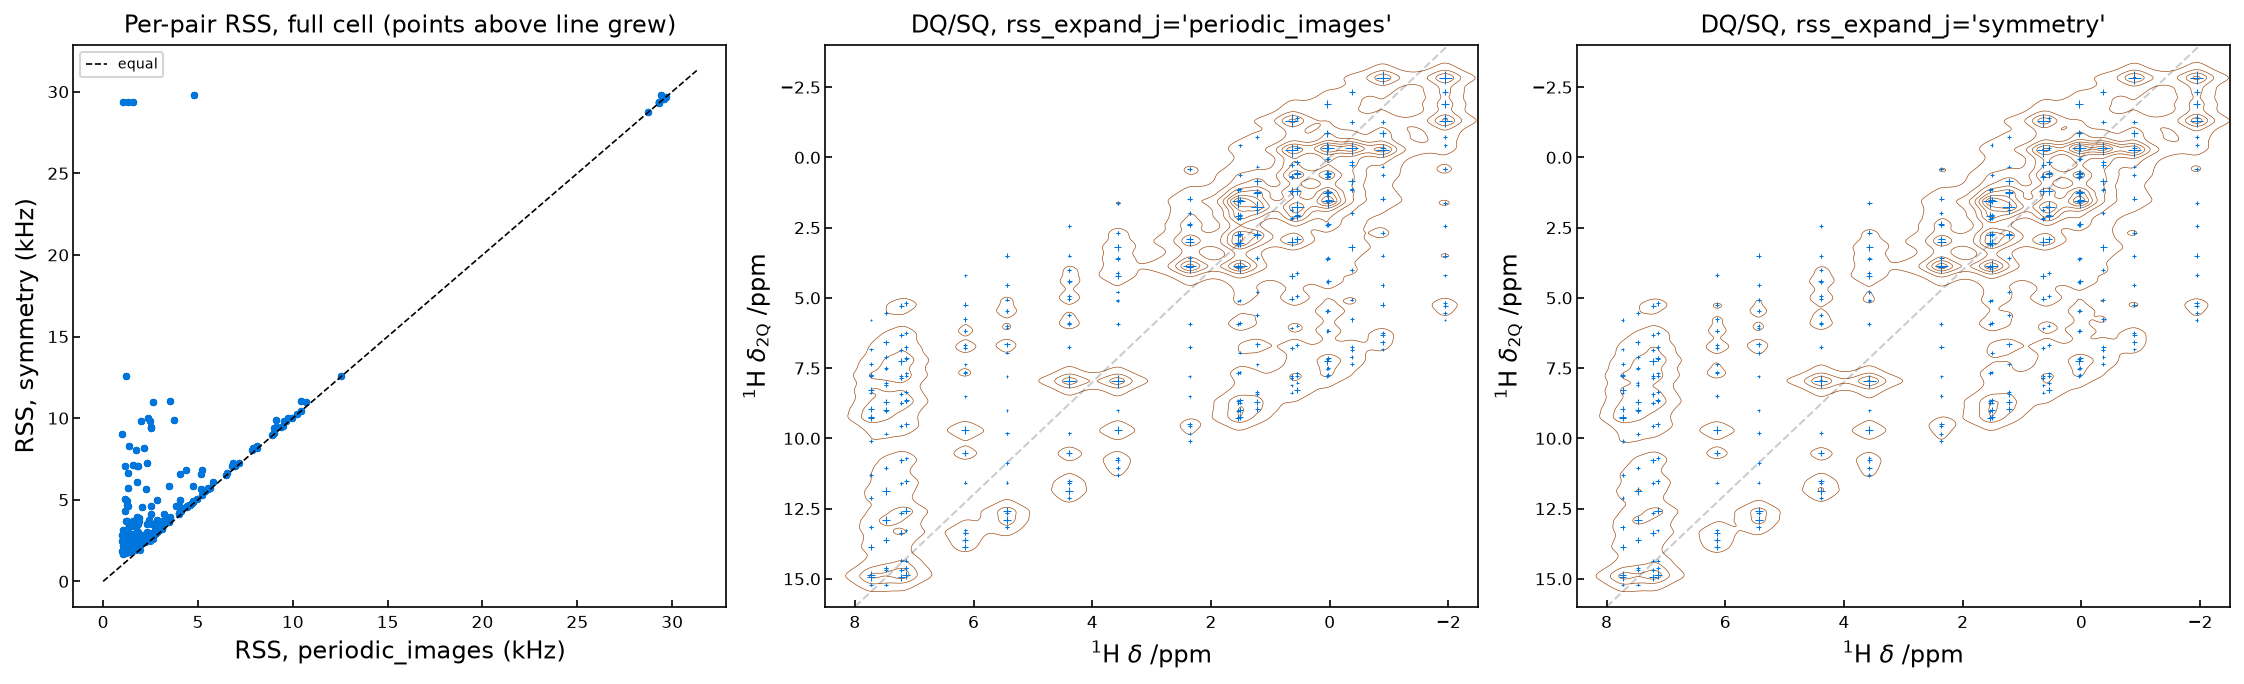

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
axes[0].scatter(pbc_strength, sym_strength, s=6, alpha=0.5, color='C0')
top = max(pbc_strength.max(), sym_strength.max()) * 1.05
axes[0].plot([0, top], [0, top], 'k--', lw=0.8, label='equal')
axes[0].set_xlabel('RSS, periodic_images (kHz)')
axes[0].set_ylabel('RSS, symmetry (kHz)')
axes[0].set_title('Per-pair RSS, full cell (points above line grew)')
axes[0].legend()

for ax, mode in zip(axes[1:], ['periodic_images', 'symmetry']):
    NMRPlot2D(
        NMRData2D(edizum, reduce=False, rss_expand_j=mode, **rss_kw),
        PlotSettings(
            show_contour=True, show_markers=True, show_connectors=False, show_diagonal=True,
            show_labels=False, show_lines=False, x_broadening=0.5, y_broadening=0.5,
            colormap='bone_r', contour_levels=8, contour_linewidth=0.3,
            scale_markers=True, max_marker_size=40, xlim=(-2.5, 8.5), ylim=(-4, 16),
        ),
        ax=ax,
    ).plot()
    ax.set_title(f"DQ/SQ, rss_expand_j='{mode}'")
plt.tight_layout();

*Figure: EDIZUM full-cell dipolar RSS in two expansion modes. Left: per-pair RSS comparison. Middle and right: the corresponding DQ/SQ maps (shift $\delta$, ppm).*

On the full cell, `'periodic_images'` counts only periodic copies of the one chosen second-site atom and omits equivalent protons in the other three molecules. `'symmetry'` includes them, so every point in the left panel lies on or above the dashed equality line. In the DQ/SQ maps, `'periodic_images'` retains more unmerged peaks, whereas in `'symmetry'` mode symmetry-equivalent pairs obtain identical RSS values and merge cleanly. `'symmetry'` and `'cif_labels'` agree identically here because the CIF labels match the space-group symmetry.

With `reduce=True`, both modes already give identical results, as confirmed below.

In [23]:
pd.DataFrame({
    'median RSS ratio, symmetry / periodic_images (full cell)': [round(float(np.median(ratio)), 2)],
    '95th percentile ratio': [round(float(np.percentile(ratio, 95)), 2)],
    'largest RSS difference, reduced cell (kHz)': [float(reduced_gap)],
}, index=['EDIZUM'])

,"median RSS ratio, symmetry / periodic_images (full cell)",95th percentile ratio,"largest RSS difference, reduced cell (kHz)"
EDIZUM,1.3,4.4,0.0


On the full cell, the median pair grows by a factor of about 1.3 (and the 95th percentile by more than 4×). In the reduced structure the maximum difference is zero, confirming that `reduce=True` already gathers all equivalent atoms into each site.

**Practical takeaway:** `rss_expand_j` matters only when working on the full unit cell (`reduce=False`). For reduced workflows (`reduce=True`), the default `'periodic_images'` is already complete. On a full cell, choose `'symmetry'` to include all symmetry-equivalent neighbours, or `'cif_labels'` if you prefer to follow the file's CIF labelling. Keep in mind that dipolar RSS remains a structural proxy rather than a full DQ build-up calculation; in practice, motional averaging ([Dipolar averaging](../dipolar-averaging)) often has a larger effect than the choice of `rss_expand_j`.

## 13 - Summary and next steps

In this tutorial you built and customised 2D NMR correlation maps from `.magres` files:

- Used `NMRData2D` to pair sites and compute correlation strengths (`Peak2D` objects), `PlotSettings` to configure visual options, and `NMRPlot2D` to plot them.
- Switched between shielding ($\sigma$, ascending axes) and chemical shift ($\delta$, reversed axes) by passing `references` for the plotted elements.
- Filtered pairs by minimum-image distance (`rcut`) and compared `'fixed'`, `'dipolar'`, `'jcoupling'`, and `'dipolar_rss'` weighting metrics.
- Customised maps with explicit `pairs`/`correlation_strengths`, standalone `Peak2D` objects, in-place edits, and fast-rotation functional-group averaging (`average_group='CH3'`, `'CH3,NH3'`).
- Built heteronuclear C–H maps, homonuclear ¹H–¹H DQ/SQ maps, and combined 2D + 1D margin figures, then exported peak lists (CSV) and contour grids (ssNake JSON, NPZ, CSV).

**Next steps:** [Tutorial 5c](./05c-nmr-tensors-spin-systems.ipynb) covers tensor orientations and spin systems for full spin-dynamics simulations in SIMPSON and MRSimulator. For deeper reference on the underlying physics and conventions, see [Chemical shift referencing](../chemical-shift-referencing), [Dipolar averaging](../dipolar-averaging), and [SIMPSON tensor conventions](../simpson-conventions).